In [1]:
!pip install pymoo matplotlib -q

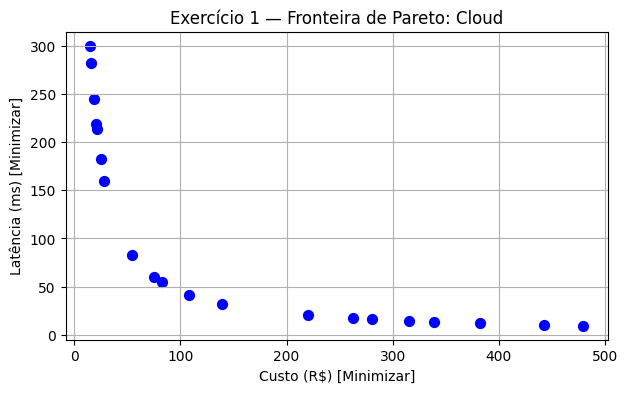

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class CloudProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=1, n_obj=2, xl=np.array([1.0]), xu=np.array([32.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        vcpus = x[0]
        f1_custo = vcpus * 15.0         # R$ 15 por vCPU
        f2_latencia = 300.0 / vcpus     # Latência cai com mais vCPUs
        out["F"] = [f1_custo, f2_latencia]

res1 = minimize(CloudProblem(), NSGA2(pop_size=20), termination=('n_gen', 30), seed=1)

# Visualização
plt.figure(figsize=(7, 4))
plt.scatter(res1.F[:, 0], res1.F[:, 1], color='blue', s=50)
plt.title("Exercício 1 — Fronteira de Pareto: Cloud")
plt.xlabel("Custo (R$) [Minimizar]")
plt.ylabel("Latência (ms) [Minimizar]")
plt.grid(True)
plt.show()

In [4]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class SOCAllocationProblem(ElementwiseProblem):
    def __init__(self):
        # 2 variáveis (x1: 1 a 50 analistas, x2: 1 a 10 regimento de segurança)
        # 2 objetivos a serem minimizados
        super().__init__(
            n_var=2,
            n_obj=2,
            xl=np.array([1.0, 1.0]),
            xu=np.array([50.0, 10.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):
        analistas, regimento = x[0], x[1]

        # Fórmula do Custo (R$ 100 por analista + R$ 50 por regimento)
        f1_custo = (analistas * 100.0) + (regimento * 50.0)

        # Tempo de Resposta em minutos (200 / analistas + 50 / regimento)
        f2_tempo = (200.0 / analistas) + (50.0 / regimento)

        out["F"] = [f1_custo, f2_tempo]

# Instancia o algoritmo NSGA2 com pop_size=30 e executa com 40 gerações
algoritmo = NSGA2(pop_size=30)
res2 = minimize(SOCAllocationProblem(), algoritmo, termination=('n_gen', 40), seed=42)

print("Soluções do Exercício 2 (Custo, Tempo):")
print(res2.F[:5]) # Exibe as 5 primeiras soluções

Soluções do Exercício 2 (Custo, Tempo):
[[5499.15144291    9.00078892]
 [ 150.09223137  249.82575583]
 [4566.67075111    9.92824149]
 [ 639.59112553   57.59677282]
 [2419.49997264   15.42802542]]


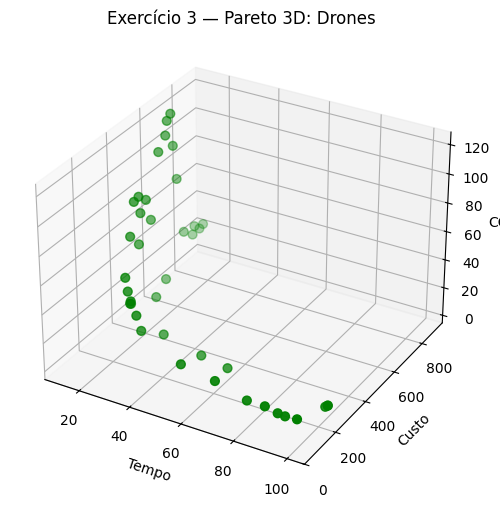

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class DroneProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=3, xl=np.array([10.0, 1.0]), xu=np.array([80.0, 5.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        velocidade, carga = x[0], x[1]
        f1_tempo = 1000.0 / velocidade
        f2_custo = (velocidade ** 2) * 0.1 + (carga * 50)
        f3_co2 = (velocidade * 1.5) / carga
        out["F"] = [f1_tempo, f2_custo, f3_co2]

res3 = minimize(DroneProblem(), NSGA2(pop_size=40), termination=('n_gen', 50), seed=42)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(res3.F[:, 0], res3.F[:, 1], res3.F[:, 2], color='green', s=40)
ax.set_xlabel("Tempo")
ax.set_ylabel("Custo")
ax.set_zlabel("CO2")
plt.title("Exercício 3 — Pareto 3D: Drones")
plt.show()

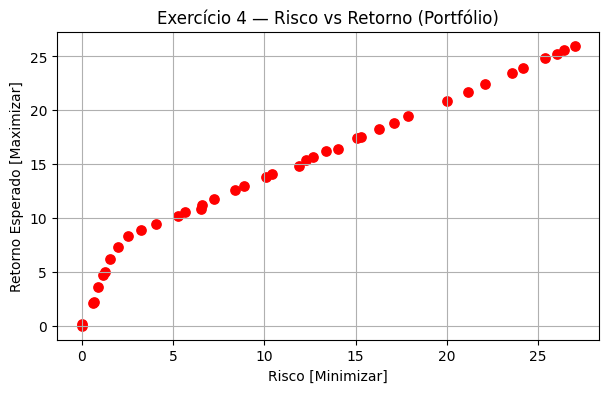

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class PortfolioProblem(ElementwiseProblem):
    def __init__(self):
        # x1: % Renda Fixa (0 a 100), x2: % Ações (0 a 100)
        super().__init__(n_var=2, n_obj=2, xl=np.array([0.0, 0.0]), xu=np.array([100.0, 100.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        rf, acoes = x[0], x[1]

        # Retorno Esperado. Sinal invertido para maximizar.
        f1_retorno_negativo = -(rf * 0.08 + acoes * 0.18)

        # Risco a ser minimizado
        f2_risco = (rf * 0.02 + acoes * 0.25)

        out["F"] = [f1_retorno_negativo, f2_risco]

# Executa o NSGA-II
res4 = minimize(PortfolioProblem(), NSGA2(pop_size=40), termination=('n_gen', 50), seed=42)

# Reverte o sinal do retorno para o gráfico
retorno_real = -res4.F[:, 0]
risco = res4.F[:, 1]

# Plota o Risco (eixo X) versus Retorno Real (eixo Y)
plt.figure(figsize=(7, 4))
plt.scatter(risco, retorno_real, color='red', s=45)
plt.title("Exercício 4 — Risco vs Retorno (Portfólio)")
plt.xlabel("Risco [Minimizar]")
plt.ylabel("Retorno Esperado [Maximizar]")
plt.grid(True)
plt.show()

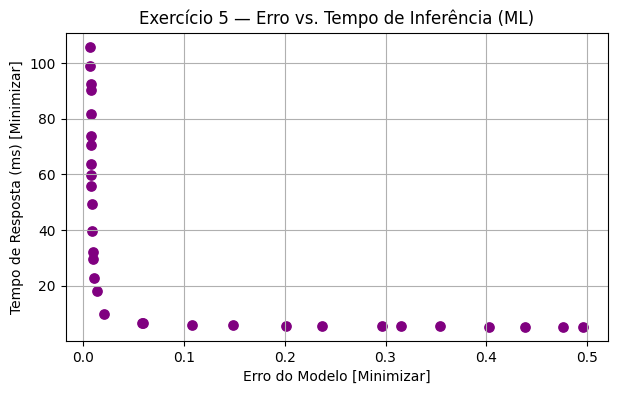

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class MLTuningProblem(ElementwiseProblem):
    def __init__(self):
        # x1: Profundidade da Árvore (1 a 30), x2: Número de Estimadores (10 a 200)
        super().__init__(n_var=2, n_obj=2, xl=np.array([1.0, 10.0]), xu=np.array([30.0, 200.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        depth, n_trees = x[0], x[1]
        f1_erro = 0.5 / (depth * np.log10(n_trees))   # Erro cai com mais árvores/profundidade
        f2_latencia_ms = (depth * 0.2) + (n_trees * 0.5) # Latência sobe
        out["F"] = [f1_erro, f2_latencia_ms]

res5 = minimize(MLTuningProblem(), NSGA2(pop_size=30), termination=('n_gen', 40), seed=7)

plt.figure(figsize=(7, 4))
plt.scatter(res5.F[:, 0], res5.F[:, 1], color='purple', s=45)
plt.title("Exercício 5 — Erro vs. Tempo de Inferência (ML)")
plt.xlabel("Erro do Modelo [Minimizar]")
plt.ylabel("Tempo de Resposta (ms) [Minimizar]")
plt.grid(True)
plt.show()

In [9]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class EVBatteryProblem(ElementwiseProblem):
    def __init__(self):
        # 2 variáveis, 2 objetivos e 1 RESTRIÇÃO de desigualdade (n_ieq_constr=1)
        super().__init__(n_var=2, n_obj=2, n_ieq_constr=1, xl=np.array([10.0, 15.0]), xu=np.array([150.0, 45.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        potencia, temp = x[0], x[1]

        f1_tempo_recarga = 3000.0 / potencia
        f2_desgaste_bateria = (potencia ** 1.5) * (temp / 20.0)

        # Restrição: G(x) <= 0
        g1 = f2_desgaste_bateria - 1500.0

        out["F"] = [f1_tempo_recarga, f2_desgaste_bateria]

        # Passa a restrição para a saída
        out["G"] = [g1]

# Executa a otimização com o NSGA-II
res6 = minimize(EVBatteryProblem(), NSGA2(pop_size=40), termination=('n_gen', 50), seed=42)

# Imprime no console apenas as soluções viáveis
print("Exercício 6 - Soluções viáveis (Tempo de Recarga, Desgaste):")
print(res6.F)

Exercício 6 - Soluções viáveis (Tempo de Recarga, Desgaste):
[[ 299.98604101   23.71885687]
 [  20.00000264 1377.84937661]
 [ 199.88258764   43.62184173]
 [ 225.49117934   36.43538683]
 [ 110.09457407  106.68366754]
 [  88.13888565  148.94052149]
 [ 279.75495309   26.7701596 ]
 [ 102.54342556  118.70305345]
 [  65.95756475  230.07386301]
 [  24.66962036 1005.77384402]
 [ 140.41598948   74.0670296 ]
 [  22.52647754 1152.67080786]
 [  31.22086641  706.4442845 ]
 [ 191.40494603   46.53884795]
 [  50.75745971  340.7951525 ]
 [ 128.18176165   84.93452626]
 [  34.65669197  604.96460205]
 [ 269.93237692   27.7890969 ]
 [  81.54010929  170.21114393]
 [  42.03613343  452.18073953]
 [  37.73751663  531.59937479]
 [ 240.11668469   33.12175313]
 [ 176.30568202   52.64409924]
 [  39.71511117  492.39341786]
 [  57.44964052  285.67406107]
 [  58.9169561   282.77232303]
 [  25.77986544  941.54751728]
 [  23.62471253 1073.24069007]
 [ 256.67884744   29.96843348]
 [ 153.25738777   64.95566518]
 [  74.06


--- Exercício 7: As 3 melhores soluções de trade-off ---
1. Menor Custo : Custo = 133.02 mil | Tempo = 63.95 min
2. Solução Intermediária: Custo = 243.41 mil | Tempo = 30.88 min
3. Menor Tempo : Custo = 530.30 mil | Tempo = 17.93 min


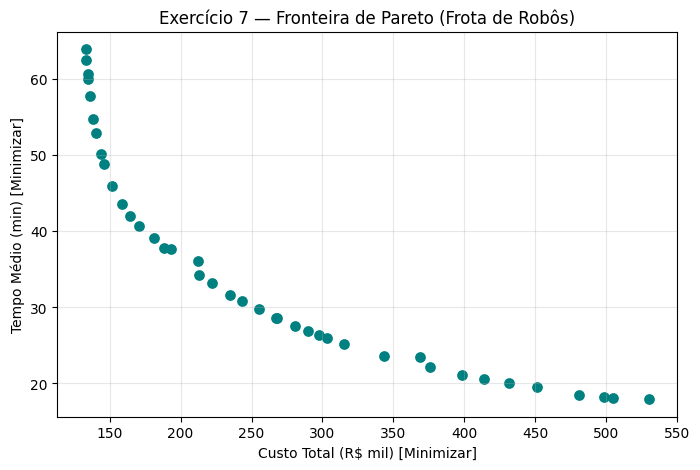

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class FrotaRobosProblem(ElementwiseProblem):
    def __init__(self):
        # Variáveis: Frota (5 a 50) e Velocidade (1.0 a 4.0)
        super().__init__(n_var=2, n_obj=2, n_ieq_constr=1, xl=np.array([5.0, 1.0]), xu=np.array([50.0, 4.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        x1, x2 = x[0], x[1]

        # Objetivo 1: Custo Total
        f1_custo = (x1 * 25.0) + ((x2 ** 2) * 8.0)

        # Objetivo 2: Tempo Médio
        f2_tempo = (120.0 / x1) + (40.0 / x2)

        # Restrição de Energia: x1 * (x2^1.5) <= 120.0 -> G(x) <= 0
        g1_energia = (x1 * (x2 ** 1.5)) - 120.0

        out["F"] = [f1_custo, f2_tempo]
        out["G"] = [g1_energia]

# Configura o NSGA-II e roda por 60 gerações
res7 = minimize(FrotaRobosProblem(), NSGA2(pop_size=40), termination=('n_gen', 60), seed=42)

# Extrair e ordenar soluções por custo
F_res = res7.F
ordem_custo = np.argsort(F_res[:, 0])
F_ordenado = F_res[ordem_custo]

print("\n--- Exercício 7: As 3 melhores soluções de trade-off ---")
print(f"1. Menor Custo : Custo = {F_ordenado[0][0]:.2f} mil | Tempo = {F_ordenado[0][1]:.2f} min")
print(f"2. Solução Intermediária: Custo = {F_ordenado[len(F_ordenado)//2][0]:.2f} mil | Tempo = {F_ordenado[len(F_ordenado)//2][1]:.2f} min")
print(f"3. Menor Tempo : Custo = {F_ordenado[-1][0]:.2f} mil | Tempo = {F_ordenado[-1][1]:.2f} min")

# Gráfico da Fronteira de Pareto
plt.figure(figsize=(8, 5))
plt.scatter(res7.F[:, 0], res7.F[:, 1], color='teal', s=45)
plt.title("Exercício 7 — Fronteira de Pareto (Frota de Robôs)")
plt.xlabel("Custo Total (R$ mil) [Minimizar]")
plt.ylabel("Tempo Médio (min) [Minimizar]")
plt.grid(True, alpha=0.3)
plt.show()